<a href="https://colab.research.google.com/github/santidrelew/tp-mpg/blob/main/notebooks/02_extraccion_muestra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **2 - Extracción de la muestra**

In [1]:
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !git clone https://github.com/santidrelew/tp-mpg.git
    %cd tp-mpg

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In [3]:
# Cargamos los datasets
PROJECT_DIR = Path().resolve() if EN_COLAB else Path().resolve().parent
DATA_BASE_DIR = PROJECT_DIR / "datos" / "procesados"

df = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_filtrado.csv")

Vamos a hacer un muestreo estratificado tomando como estrato la variable 'neighbourhood_cleansed'. Esto es porque las tarifas y amenidades difieren sustancialmente entre el centro historico y las comunas perifericas. Un muestreo puramente aleatorio corria el riesgo de subestimar zonas de menor densidad de oferta (como la comuna 7).

In [4]:
N_MUESTRA = 750
zona = "neighbourhood_cleansed"
fraccion = N_MUESTRA / len(df)

df_muestra = pd.concat([
    grupo.sample(frac=fraccion, random_state=42)
    for _, grupo in df.groupby(zona, sort=True)
])

if len(df_muestra) > N_MUESTRA:
    df_muestra = df_muestra.sample(n=N_MUESTRA, random_state=42)

assert zona in df_muestra.columns
assert len(df_muestra) == N_MUESTRA

In [5]:
TARGET = "log_daily_price"

media_pop = df[TARGET].mean()
var_pop = df[TARGET].var()

media_mue = df_muestra[TARGET].mean()
var_mue = df_muestra[TARGET].var()

tabla_validacion = pd.DataFrame(
    {
        "Metrica": [
            "Media ",
            "Varianza",
            "Desvio Estándar ",
            "Mediana ",
        ],
        "Poblacion": [
            round(media_pop, 2),
            round(var_pop, 2),
            round(df[TARGET].std(), 2),
            round(df[TARGET].median(), 2),
        ],
        "Muestra (n=750)": [
            round(media_mue, 2),
            round(var_mue, 2),
            round(df_muestra[TARGET].std(), 2),
            round(df_muestra[TARGET].median(), 2),
        ],
        "Diferencia Relativa (%)": [
            round(abs(media_pop - media_mue) / media_pop * 100, 2),
            round(abs(var_pop - var_mue) / var_pop * 100, 2),
            round(
                abs(df[TARGET].std() - df_muestra[TARGET].std())
                / df[TARGET].std()
                * 100,
                2,
            ),
            round(
                abs(df[TARGET].median() - df_muestra[TARGET].median())
                / df[TARGET].median()
                * 100,
                2,
            ),
        ],
    }
)

tabla_validacion

,Metrica,Poblacion,Muestra (n=750),Diferencia Relativa (%)
0,Media,4.44,4.42,0.46
1,Varianza,0.30,0.27,10.30
2,Desvio Estándar,0.55,0.52,5.29
3,Mediana,4.33,4.33,0.00



Poblacion
Percentil 95: 5.48 | Percentil 99: 6.22 | Máximo: 8.01

Muestra
Percentil 95: 5.30 | Percentil 99: 6.19 | Máximo: 7.09


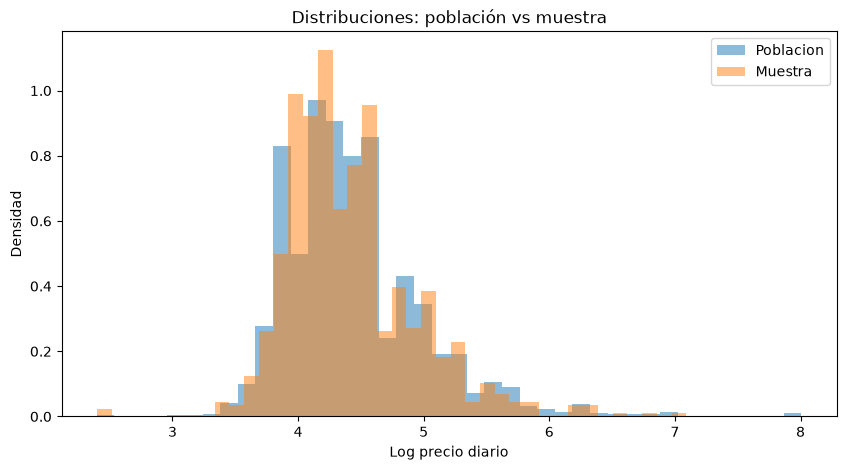

In [6]:
for nombre, datos in [
    ("Poblacion", df[TARGET]),
    ("Muestra", df_muestra[TARGET])
]:
    print(f"\n{nombre}")
    print(
        f"Percentil 95: {datos.quantile(0.95):.2f} | "
        f"Percentil 99: {datos.quantile(0.99):.2f} | "
        f"Máximo: {datos.max():.2f}"
    )
    
plt.figure(figsize=(10, 5))

plt.hist(
    df[TARGET],
    bins=40,
    density=True,
    alpha=0.5,
    label="Poblacion"
)

plt.hist(
    df_muestra[TARGET],
    bins=40,
    density=True,
    alpha=0.5,
    label="Muestra"
)

plt.xlabel("Log precio diario")
plt.ylabel("Densidad")
plt.title("Distribuciones: población vs muestra")
plt.legend()
plt.show()

In [7]:
proporciones = pd.DataFrame({
    "Base (%)": df[zona].value_counts(normalize=True) * 100,
    "Muestra (%)": df_muestra[zona].value_counts(normalize=True) * 100,
}).fillna(0).sort_index()
proporciones["Diferencia (p. p.)"] = (
    proporciones["Muestra (%)"] - proporciones["Base (%)"]
)

display(proporciones.round(2))

,Base (%),Muestra (%),Diferencia (p. p.)
neighbourhood_cleansed,,,
1,17.62,17.60,-0.02
2,12.79,12.80,0.01
3,11.71,11.73,0.02
4,10.06,10.00,-0.06
5,9.37,9.33,-0.04
6,12.37,12.40,0.03
7,7.14,7.20,0.06
8,9.77,9.73,-0.03
9,9.18,9.20,0.02


Como la media del log-precio difiere solo un 0,46 % respecto de la base filtrada y la mediana que es menos sensible a los valores extremos, coincide en 4.33 podemos decir que la muestra refleja bien el centro de la distribucion. Además, conserva las proporciones de anuncios por zona con una diferencia maxima 0.06 puntos porcentuales.

En cuanto a la varianza y el desvio ambos son menores en la muestra, con diferencias del 10,30 % y del 5,29 %, respectivamente. Una posible explicación es que la muestra haya captado menos observaciones de la parte mas extrema de la distribuciin. Esto tambien se observa al comparar los percentiles. Estas diferencias por si solas no indican un sesgo de muestreo.

El uso de `log_daily_price` permite comprimir las diferencias entre los precios mas elevados y moderar su influencia en la regresión aunque no elimina porcompleto  el efecto de los valores extremos.

In [8]:
# Guardamos la muestra
df_muestra.to_csv(DATA_BASE_DIR / "milan_airbnb_muestra.csv", index=False)